<a href="https://colab.research.google.com/github/nilaynishant/acrs/blob/main/07_Feature_Importance_and_Explainability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# Notebook 3 – Feature Importance & Model Explainability
### GeoAI for Future Earth | ACRS Training Workshop 2026

**Learning objectives:**
- Interpret RF predictions with **native (impurity-based) feature importance**
- Understand **permutation importance** as a model-agnostic alternative
- Apply **SHAP (SHapley Additive exPlanations)** to RF and XGBoost
- Visualise global and per-class feature contributions with SHAP plots


## 0 · Setup

In [ ]:
%%capture
!pip install rioxarray geopandas xarray scikit-learn xgboost shap matplotlib seaborn


## 1 · Data Preparation & Model Training
*(Standalone – re-runs preprocessing and trains tuned RF + XGBoost)*

In [ ]:
import os, subprocess, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import rioxarray as rxr
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

# ── Clone repository ──────────────────────────────────────────
REPO_URL = 'https://github.com/nilaynishant/AIMLTutorial.git'
REPO_DIR = '/content/AIMLTutorial'
if not os.path.exists(REPO_DIR):
    subprocess.run(['git', 'clone', '--depth=1', REPO_URL, REPO_DIR],
                   capture_output=True, check=True)
    print("Repository cloned.")
else:
    print("Repository already present.")

RASTER_PATH = f'{REPO_DIR}/Data/Sentinel2_Agartala.tif'
POINTS_PATH = f'{REPO_DIR}/Data/Training.gpkg'

# ── Load raster and assign band names ────────────────────────
# Bands in the TIF: Band1=B8A(NIR), Band2=B4(Red), Band3=B3(Green), Band4=B2(Blue)
img = rxr.open_rasterio(RASTER_PATH).assign_coords(band=['B8A', 'B4', 'B3', 'B2'])
img_ref = img.astype(float) / 10000.0   # scale DN → surface reflectance

nir, red, green, blue = (img_ref.sel(band=b) for b in ['B8A', 'B4', 'B3', 'B2'])

# ── Spectral indices ──────────────────────────────────────────
ndvi = (nir - red)   / (nir + red)
ndwi = (green - nir) / (green + nir)
savi = 1.5 * (nir - red) / (nir + red + 0.5)
evi  = (2.5 * (nir - red) / (nir + 6*red - 7.5*blue + 1)).clip(-2, 2)

def _band(da, name):
    return da.expand_dims({'band': [name]})

stacked = xr.concat([
    img_ref,
    _band(ndvi, 'NDVI'), _band(ndwi, 'NDWI'),
    _band(savi, 'SAVI'), _band(evi,  'EVI')
], dim='band')

FEATURE_NAMES = stacked.band.values.tolist()
CLASS_MAP = {1: 'Vegetation', 2: 'Builtup', 3: 'Water', 4: 'Agriculture', 5: 'Fallow'}
LULC_COLORS = ['#2ECC71', '#E74C3C', '#3498DB', '#F1C40F', '#95A5A6']

# ── Sample pixel values at training points ────────────────────
gdf = gpd.read_file(POINTS_PATH).to_crs(stacked.rio.crs)
xs = xr.DataArray(gdf.geometry.x.values, dims=['pts'])
ys = xr.DataArray(gdf.geometry.y.values, dims=['pts'])
sampled = stacked.sel(x=xs, y=ys, method='nearest')  # (bands, n_pts)

df = pd.DataFrame(sampled.values.T, columns=FEATURE_NAMES)
df.insert(0, 'label',      gdf['id'].values)
df.insert(1, 'class_name', df['label'].map(CLASS_MAP))

print(f"Features ({len(FEATURE_NAMES)}): {FEATURE_NAMES}")
print(f"Training samples: {len(df)}  |  Classes: {df['label'].nunique()}")
df.head()


Repository cloned.
Features (8): ['B8A', 'B4', 'B3', 'B2', 'NDVI', 'NDWI', 'SAVI', 'EVI']
Training samples: 51  |  Classes: 5


,label,class_name,B8A,B4,B3,B2,NDVI,NDWI,SAVI,EVI
0,1,Vegetation,0.2353,0.0430,0.0569,0.0446,0.690981,-0.610541,0.370615,0.414869
1,1,Vegetation,0.2664,0.0500,0.0601,0.0446,0.683944,-0.631853,0.397599,0.439159
2,1,Vegetation,0.2628,0.0451,0.0577,0.0433,0.707048,-0.639938,0.404196,0.450296
3,1,Vegetation,0.2335,0.0481,0.0613,0.0476,0.658381,-0.584125,0.355809,0.397820
4,1,Vegetation,0.2535,0.0679,0.0795,0.0607,0.577474,-0.522523,0.338934,0.384855


In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

X = df[FEATURE_NAMES].values
y = df['label'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

scaler     = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Tuned RF
rf_gs = GridSearchCV(
    RandomForestClassifier(random_state=42),
    {'n_estimators': [100, 200], 'max_depth': [None, 10], 'max_features': ['sqrt', 'log2']},
    cv=cv, scoring='accuracy', n_jobs=-1)
rf_gs.fit(X_train, y_train)
best_rf = rf_gs.best_estimator_

# Tuned XGBoost
xgb_gs = GridSearchCV(
    XGBClassifier(use_label_encoder=False, eval_metric='mlogloss',
                  random_state=42, verbosity=0),
    {'n_estimators': [100, 200], 'max_depth': [3, 5], 'learning_rate': [0.1, 0.3]},
    cv=cv, scoring='accuracy', n_jobs=-1)
xgb_gs.fit(X_train, y_train - 1)
best_xgb = xgb_gs.best_estimator_

print(f"RF  best CV acc  : {rf_gs.best_score_*100:.1f}%  | {rf_gs.best_params_}")
print(f"XGB best CV acc : {xgb_gs.best_score_*100:.1f}%  | {xgb_gs.best_params_}")


RF  best CV acc  : 85.7%  | {'max_depth': None, 'max_features': 'log2', 'n_estimators': 200}
XGB best CV acc : 82.9%  | {'learning_rate': 0.3, 'max_depth': 3, 'n_estimators': 200}


## 2 · RF Native Feature Importance (Impurity / Gini)

Random Forest accumulates the **mean decrease in Gini impurity** across all trees for each
feature. While fast to compute, this method can overestimate continuous or high-cardinality
features. Always cross-check with permutation or SHAP importance.


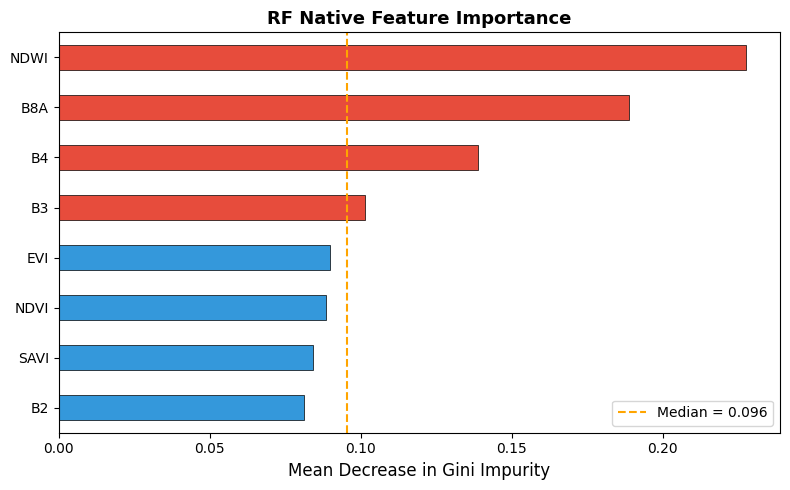


Feature importances (sorted):
NDWI    0.227381
B8A     0.188742
B4      0.138948
B3      0.101370
EVI     0.089803
NDVI    0.088461
SAVI    0.084036
B2      0.081258


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Extract and sort importances
rf_importances = pd.Series(best_rf.feature_importances_, index=FEATURE_NAMES)
rf_importances = rf_importances.sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
colors_bars = ['#E74C3C' if v > rf_importances.median() else '#3498DB'
               for v in rf_importances]
rf_importances.plot(kind='barh', ax=ax, color=colors_bars, edgecolor='black', linewidth=0.5)
ax.axvline(rf_importances.median(), color='orange', linestyle='--', linewidth=1.5,
           label=f'Median = {rf_importances.median():.3f}')
ax.set_xlabel('Mean Decrease in Gini Impurity', fontsize=12)
ax.set_title('RF Native Feature Importance', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

print("\nFeature importances (sorted):")
print(rf_importances.sort_values(ascending=False).to_string())
